In [2]:
# Importing necessary libraries and functions
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import f1_score, accuracy_score
import wandb
from tqdm import tqdm
import librosa
import librosa.display

In [3]:
# Data paths and configs

DATA_ROOT = "../data/messy_mashup/genres_stems"
NOISE_DIR = "../data/messy_mashup/ESC-50-master/audio"
MODEL_DIR = "../models"

GENRES = ["blues", "classical", "country", "disco", "hiphop",
                "jazz", "metal", "pop", "reggae", "rock"]
GENRE_TO_IDX = {g: i for i, g in enumerate(GENRES)}
STEMS = ["drums", "vocals", "bass", "other"]


SR_CRNN = 22050
DURATION = 10.0
N_MELS = 128
N_FFT = 2048
HOP_LENGTH = 256
SAMPLES_PER_GENRE = 200
VAL_SPLIT = 0.2
BATCH_SIZE = 32
DATA_SEED = 67
TRAINING_SEED = 1234

GAIN_MIN = 0.5
GAIN_MAX = 1.5
STRETCH_MIN = 0.85
STRETCH_MAX = 1.15
SNR_MIN_DB = 5.0
SNR_MAX_DB = 20.0

random.seed(TRAINING_SEED)
np.random.seed(TRAINING_SEED)
torch.manual_seed(TRAINING_SEED)
torch.cuda.manual_seed_all(TRAINING_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


In [4]:
# Helper functions (from eda_and_process notebook)

def _pad_or_trim(y, target_len):
    if len(y) >= target_len:
        return y[:target_len]
    return np.pad(y, (0, target_len - len(y)))


def make_augmented_mix(genre, data_root, sr, duration, rng):
    """
    Build one training sample via cross-song stem mixing.
    Each of the 4 stems is drawn from a independently chosen song of the
    same genre, simulating the cross-song recombination in the test mashups.
    Per-stem random gain, time-stretch, and variable-SNR ESC-50 noise are
    applied before peak normalisation.
    """
    target_len = int(sr * duration)
    genre_dir = os.path.join(data_root, genre)
    songs = sorted(os.listdir(genre_dir))
    mix = np.zeros(target_len, dtype=np.float32)

    for stem in STEMS:
        song = rng.choice(songs)
        path = os.path.join(genre_dir, song, f"{stem}.wav")
        try:
            y, _ = librosa.load(path, sr=sr)
            # random crop if stem is longer than target
            if len(y) > target_len:
                start = rng.randint(0, len(y) - target_len)
                y = y[start: start + target_len]
            else:
                y = _pad_or_trim(y, target_len)
            gain = rng.uniform(GAIN_MIN, GAIN_MAX)
            mix += y * gain
        except Exception:
            pass

    # time stretch removed, too slow for on-the-fly augmentation
    # and causes spectrogram time dimension instability
    # rate = rng.uniform(STRETCH_MIN, STRETCH_MAX)
    # try:
    #     mix = librosa.effects.time_stretch(mix, rate=rate)
    # except Exception:
    #     pass
    # mix = _pad_or_trim(mix, target_len)

    # add ESC-50 noise at a random SNR
    noise_files = [f for f in os.listdir(NOISE_DIR) if f.endswith(".wav")]
    try:
        noise, _ = librosa.load(
            os.path.join(NOISE_DIR, rng.choice(noise_files)), sr=sr
        )
        noise = _pad_or_trim(noise, target_len)
        snr_db = rng.uniform(SNR_MIN_DB, SNR_MAX_DB)
        sig_rms = np.sqrt(np.mean(mix ** 2)) + 1e-9
        noise_rms = np.sqrt(np.mean(noise ** 2)) + 1e-9
        target_rms = sig_rms / (10 ** (snr_db / 20.0))
        mix = mix + noise * (target_rms / noise_rms)
    except Exception:
        pass

    peak = np.max(np.abs(mix))
    if peak > 0:
        mix /= (peak + 1e-9)
    return mix

class GenreDatasetCRNN(Dataset):
    """
    Generates augmented mel-spectrogram tensors for CRNN training.
    Each __getitem__ call builds a fresh cross-song mix on the fly.
    """

    def __init__(self, genres, data_root, sr, duration, n_mels, n_fft, hop_length,
                 samples_per_genre=SAMPLES_PER_GENRE, seed=TRAINING_SEED):
        self.genres = genres
        self.data_root = data_root
        self.sr = sr
        self.duration = duration
        self.n_mels = n_mels
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.samples_per_genre = samples_per_genre
        self.seed = seed
        # each item is (genre, sample_index) — index drives the rng seed
        self.items = [(g, i) for g in genres for i in range(samples_per_genre)]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        genre, sample_idx = self.items[idx]
        rng = random.Random(self.seed + idx)
        mix = make_augmented_mix(genre, self.data_root, self.sr, self.duration, rng)

        S = librosa.feature.melspectrogram(
            y=mix, sr=self.sr, n_mels=self.n_mels,
            n_fft=self.n_fft, hop_length=self.hop_length
        )
        S_db = librosa.power_to_db(S, ref=np.max).astype(np.float32)
        # min-max normalise to [0, 1]
        S_db = (S_db - S_db.min()) / (S_db.max() - S_db.min() + 1e-9)
        return torch.tensor(S_db).unsqueeze(0), GENRE_TO_IDX[genre]

In [5]:
# Hyperparameters

NUM_EPOCHS = 15
LR = 3e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTH = 0.1
NUM_WORKERS = 0


In [6]:
# CRNN architecture

class CRNN(nn.Module):
    """
    3-block CNN feature extractor feeding into a 2-layer BiLSTM classifier.
    Dropout after each conv block reduces overfitting on the small training set.
    """
    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(dropout),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(dropout),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(dropout),
        )
        # after 3x MaxPool2d(2): mels = 128 // 8 = 16, channels = 128
        # lstm input = 128 * 16 = 2048
        self.lstm = nn.LSTM(
            input_size=2048,
            hidden_size=128,
            num_layers=2,
            bidirectional=True,
            batch_first=True,
            dropout=dropout
        )
        self.fc = nn.Linear(128 * 2, num_classes)

    def forward(self, x):
        x = self.cnn(x)
        b, c, f, t = x.shape
        x = x.permute(0, 3, 1, 2).reshape(b, t, c * f)
        x, _ = self.lstm(x)
        x, _ = torch.max(x, dim=1)
        return self.fc(x)

In [ ]:
# Label smoothing loss
class LabelSmoothingCE(nn.Module):
    def __init__(self, num_classes, smoothing=0.1):
        super().__init__()
        self.smoothing = smoothing
        self.num_classes = num_classes

    def forward(self, logits, targets):
        log_probs = torch.log_softmax(logits, dim=1)
        smooth_labels = torch.full_like(log_probs, self.smoothing / (self.num_classes - 1))
        smooth_labels.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        return -(smooth_labels * log_probs).sum(dim=1).mean()

In [ ]:
# Dataset and dataloaders
full_dataset = GenreDatasetCRNN(
    genres=GENRES,
    data_root=DATA_ROOT,
    sr=SR_CRNN,
    duration=DURATION,
    n_mels=N_MELS,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    samples_per_genre=SAMPLES_PER_GENRE,
    seed=DATA_SEED
)

n_val = int(len(full_dataset) * VAL_SPLIT)
n_train = len(full_dataset) - n_val
train_dataset, val_dataset = random_split(
    full_dataset, [n_train, n_val],
    generator=torch.Generator().manual_seed(DATA_SEED)
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=NUM_WORKERS)

print(f"Train samples: {n_train} | Val samples: {n_val}")

Train samples: 1600 | Val samples: 400


In [ ]:
# Model, optimizer, scheduler
model = CRNN(num_classes=len(GENRES)).to(DEVICE)
criterion = LabelSmoothingCE(num_classes=len(GENRES), smoothing=LABEL_SMOOTH)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=25)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")

Trainable parameters: 2,721,226


In [ ]:
# WandB
wandb.init(
    project="21f3002298-dl-genai-project",
    name="crnn-src-augmented-resumed-run-with-more-epochs",
    config={
        "model":           "CRNN (3-block CNN + 2-layer BiLSTM)",
        "epochs":          NUM_EPOCHS,
        "batch_size":      BATCH_SIZE,
        "lr":              LR,
        "weight_decay":    WEIGHT_DECAY,
        "label_smoothing": LABEL_SMOOTH,
        "optimizer":       "AdamW",
        "scheduler":       "CosineAnnealingLR",
        "sr":              SR_CRNN,
        "duration":        DURATION,
        "hop_length":      HOP_LENGTH,
        "samples_per_genre": SAMPLES_PER_GENRE,
        "augmentation":    "cross-song mixing, per-stem gain, time-stretch, variable SNR",
    }
)

In [ ]:
# training loop
best_val_f1 = 0.0

# Increasing the number of epochs
NUM_EPOCHS = 25

# Resuming from the previous run of 15 epochs
checkpoint_path = os.path.join(MODEL_DIR, "crnn_src_best.pth")
if os.path.exists(checkpoint_path):
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
    print("Resumed from checkpoint.")

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss, train_preds, train_labels = 0.0, [], []

    for specs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]"):
        specs, labels = specs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(specs)
        loss = criterion(logits, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        train_loss += loss.item() * specs.size(0)
        train_preds.extend(logits.argmax(dim=1).cpu().numpy())
        train_labels.extend(labels.cpu().numpy())

    scheduler.step()

    train_loss /= n_train
    train_f1 = f1_score(train_labels, train_preds, average="macro")
    train_acc = accuracy_score(train_labels, train_preds)

    model.eval()
    val_loss, val_preds, val_labels = 0.0, [], []

    with torch.no_grad():
        for specs, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]"):
            specs, labels = specs.to(DEVICE), labels.to(DEVICE)
            logits = model(specs)
            loss = criterion(logits, labels)

            val_loss += loss.item() * specs.size(0)
            val_preds.extend(logits.argmax(dim=1).cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_loss /= n_val
    val_f1 = f1_score(val_labels, val_preds, average="macro")
    val_acc = accuracy_score(val_labels, val_preds)

    wandb.log({
        "epoch":      epoch + 1,
        "train_loss": train_loss, "train_f1": train_f1, "train_acc": train_acc,
        "val_loss":   val_loss,   "val_f1":   val_f1,   "val_acc":   val_acc,
        "lr":         scheduler.get_last_lr()[0],
    })

    print(f"Epoch {epoch+1}: train_loss={train_loss:.4f} train_f1={train_f1:.4f} | "
          f"val_loss={val_loss:.4f} val_f1={val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), os.path.join(MODEL_DIR, "crnn_src_best.pth"))
        print(f"  Saved best model (val_f1={val_f1:.4f})")

Resumed from checkpoint.


Epoch 1/25 [Val]: 100%|██████████| 13/13 [01:09<00:00,  5.32s/it]


Epoch 1: train_loss=1.6526 train_f1=0.4544 | val_loss=1.5795 val_f1=0.4699
  Saved best model (val_f1=0.4699)


Epoch 2/25 [Val]: 100%|██████████| 13/13 [01:08<00:00,  5.26s/it]


Epoch 2: train_loss=1.6389 train_f1=0.4539 | val_loss=1.5546 val_f1=0.4877
  Saved best model (val_f1=0.4877)


Epoch 3/25 [Val]: 100%|██████████| 13/13 [01:07<00:00,  5.21s/it]


... (41 outputs left out)

Epoch 24/25 [Val]: 100%|██████████| 13/13 [01:08<00:00,  5.26s/it]


Epoch 24: train_loss=1.2731 train_f1=0.6550 | val_loss=1.2659 val_f1=0.6594


Epoch 25/25 [Val]: 100%|██████████| 13/13 [01:06<00:00,  5.13s/it]

Epoch 25: train_loss=1.2758 train_f1=0.6627 | val_loss=1.2640 val_f1=0.6566


In [33]:
wandb.finish()
print(f"Training complete. Best val F1: {best_val_f1:.4f}")

epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
lr,████▇▇▇▆▆▆▅▅▄▄▃▃▃▂▂▂▁▁▁▁▁
train_acc,▁▁▂▃▃▄▃▄▄▅▆▅▅▆▇▆▇▇▇██████
train_f1,▁▁▂▃▃▄▃▄▅▅▆▅▅▆▇▇▇▇███████
train_loss,██▇▆▆▆▅▅▅▄▄▄▄▃▃▃▃▂▂▁▁▁▁▁▁
val_acc,▁▁▂▂▃▃▃▂▃▄▄▄▅▆▆▅▇▇▇▇████▇
val_f1,▁▂▃▂▃▃▄▃▄▅▅▅▅▆▆▅▇▇▇▇█████
val_loss,█▇▇▇▆▆▅▆▅▄▄▄▃▂▃▃▂▂▁▂▁▁▁▁▁
epoch,25
lr,0
train_acc,0.66938


Training complete. Best val F1: 0.6661


## Inference on Val set

              precision    recall  f1-score   support

       blues     0.6190    0.7647    0.6842        34
   classical     0.8696    0.9756    0.9195        41
     country     0.4865    0.4500    0.4675        40
       disco     0.4419    0.5758    0.5000        33
      hiphop     0.6923    0.6585    0.6750        41
        jazz     0.8065    0.5682    0.6667        44
       metal     0.8000    0.9333    0.8615        30
         pop     0.7164    0.9412    0.8136        51
      reggae     0.6842    0.6047    0.6420        43
        rock     0.6364    0.3256    0.4308        43

    accuracy                         0.6775       400
   macro avg     0.6753    0.6798    0.6661       400
weighted avg     0.6798    0.6775    0.6666       400



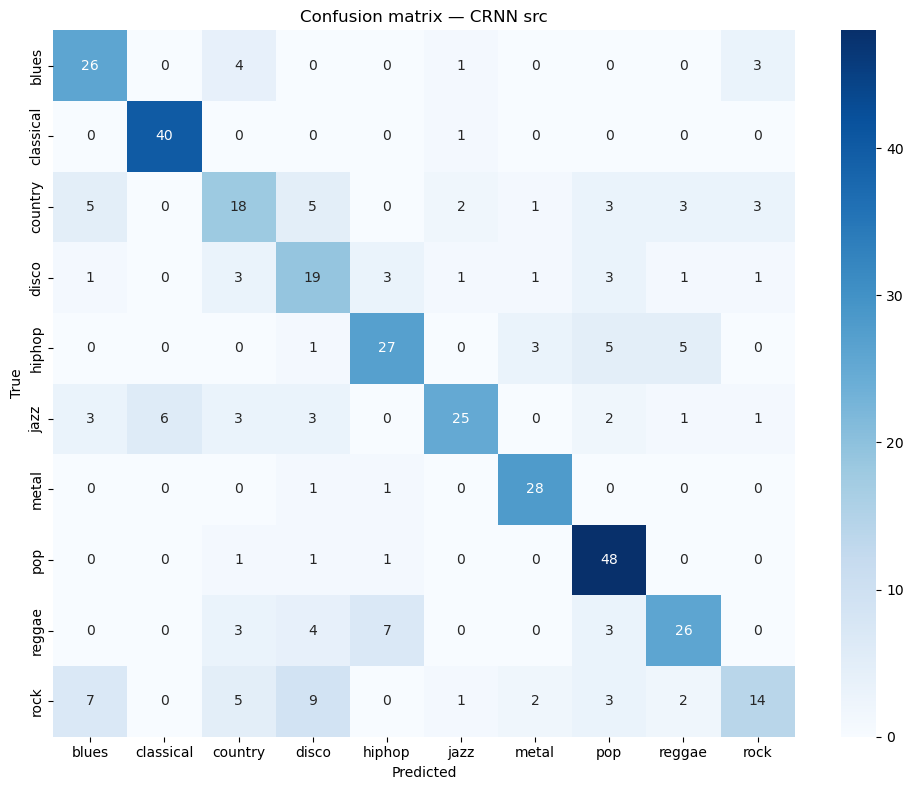

In [12]:
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

GENRES = ["blues", "classical", "country", "disco", "hiphop",
          "jazz", "metal", "pop", "reggae", "rock"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.load_state_dict(torch.load("../models/crnn_src_best.pth",
                                 map_location=DEVICE, weights_only=True))
model = model.to(DEVICE)
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in val_loader:
        outputs = model(inputs.to(DEVICE))
        all_preds.extend(outputs.argmax(dim=1).detach().cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=GENRES, digits=4))

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=GENRES, yticklabels=GENRES, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix — CRNN src")
plt.tight_layout()
plt.savefig("../models/confusion_matrix_crnn.png", dpi=150)
plt.show()

## The End